## **UTS Machine Learning** ##
- **Nama:** Maharani Putri Junaidi
- **NIM:** 241011400308
- **Kelas:** Reg CS (05TPLE005)

----

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# GANTI 8 DENGAN 2 DIGIT TERAKHIR NIM KAMU
RANDOM_STATE = 8 

def train_test_split_manual(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_size_count = int(len(X) * test_size)
    test_indices = indices[:test_size_count]
    train_indices = indices[test_size_count:]'
    ''
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

**Penjelasan Cell Persiapan (Import Library & Split Manual):**

Cell ini merupakan fondasi utama sebelum mengerjakan soal UTS. Terdapat tiga hal penting di sini:
1. **Import Library:** Memanggil `pandas` (untuk mengolah data tabel), `numpy` (untuk operasi matematika matriks/array), dan `matplotlib` (untuk membuat grafik).
2. **RANDOM_STATE = 8:** Sesuai instruksi soal, nilai ini diambil dari 2 digit terakhir NIM. Variabel ini berfungsi sebagai "kunci" agar pembagian data dan hasil model selalu konsisten (sama persis) setiap kali kode dijalankan.
3. **Fungsi `train_test_split_manual`:** Sesuai aturan UTS yang melarang penggunaan `scikit-learn`, fungsi ini dibuat secara manual menggunakan NumPy. 
   - Pertama, data diacak menggunakan `np.random.permutation` dengan *seed* dari NIM.
   - Kemudian, data dipotong. Jika `test_size=0.2`, maka 20% data terakhir dari hasil acakan akan dijadikan data *testing*, dan 80% sisanya menjadi data *training*.
   - Fungsi ini mengembalikan 4 variabel: `X_train`, `X_test`, `y_train`, dan `y_test`.

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


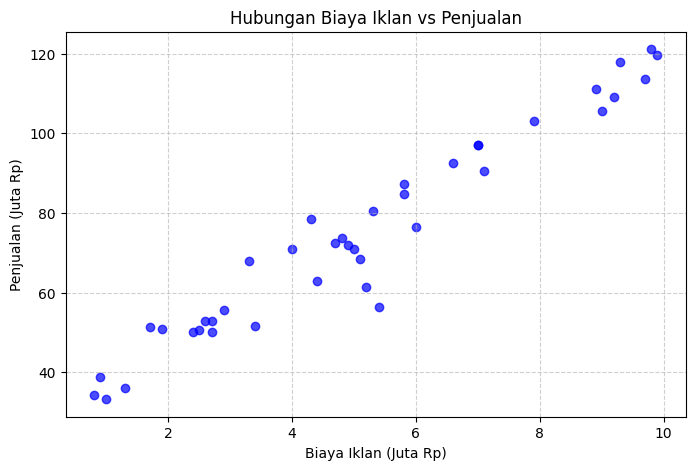

In [10]:
# Jawaban A1
df = pd.read_csv(r'C:\Users\mahrani\Downloads\Ads_Data.csv')
print("5 Data Pertama:")
print(df.head())
print(f"\nJumlah baris data: {len(df)}")

X = df['BiayaIklan'].values.reshape(-1, 1)
y = df['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7)
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Analisis A1:**
Berdasarkan scatter plot, terlihat adanya hubungan positif (linear) antara Biaya Iklan dan Penjualan. Semakin besar biaya iklan yang dikeluarkan, semakin tinggi pula penjualan yang didapat. Titik-titik data menyebar mendekati garis lurus imajiner, yang menandakan bahwa model regresi linear cocok digunakan untuk data ini.

In [26]:
# Jawaban A2
# Membagi data menjadi data training (80%) dan testing (20%)
X_train, X_test, y_train, y_test = train_test_split_manual(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Menampilkan ukuran (shape) dari masing-masing variabel
print("Shape X_train :", X_train.shape)
print("Shape X_test  :", X_test.shape)
print("Shape y_train :", y_train.shape)
print("Shape y_test  :", y_test.shape)

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


**Analisis A2:**
Data berhasil dibagi menjadi data training dan testing. Dari 40 total data, 32 data (80%) digunakan untuk melatih model (training) dan 8 data (20%) digunakan untuk menguji model (testing). Pembagian ini sesuai dengan parameter `test_size=0.2` dan `random_state=8`.

In [12]:
# Jawaban A3
class LinearRegressionManual:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1]
    def predict(self, X):
        return self.intercept_ + self.coef_ * X.flatten()

model_A3 = LinearRegressionManual()
model_A3.fit(X_train, y_train)

b = model_A3.intercept_
m = model_A3.coef_
print(f"Nilai Intercept (b): {b:.4f}")
print(f"Nilai Koefisien (m): {m:.4f}")
print(f"Persamaan garis regresi: y_hat = {b:.4f} + {m:.4f}X")

Nilai Intercept (b): 28.9945
Nilai Koefisien (m): 9.0688
Persamaan garis regresi: y_hat = 28.9945 + 9.0688X


**Interpretasi Nilai m:**
Berdasarkan hasil perhitungan, nilai koefisien (m) adalah **9.0688**.
Artinya, setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan diperkirakan akan naik sebesar **9.0688** juta Rp.

**Interpretasi Nilai b (Intercept):**
Nilai intercept (b) adalah **28.9945**. Artinya, jika biaya iklan dianggap 0 (tidak ada iklan), maka penjualan dasar yang tetap terjadi diperkirakan sebesar **28.9945** juta Rp.

In [14]:
# Jawaban A4
def mae_manual(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))
def mse_manual(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)
def rmse_manual(y_true, y_pred):
    return np.sqrt(mse_manual(y_true, y_pred))
def r2_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

y_pred_train = model_A3.predict(X_train)
y_pred_test = model_A3.predict(X_test)

eval_train = [mae_manual(y_train, y_pred_train), mse_manual(y_train, y_pred_train), rmse_manual(y_train, y_pred_train), r2_manual(y_train, y_pred_train)]
eval_test = [mae_manual(y_test, y_pred_test), mse_manual(y_test, y_pred_test), rmse_manual(y_test, y_pred_test), r2_manual(y_test, y_pred_test)]

df_eval = pd.DataFrame({
    'Data': ['Training', 'Testing'], 
    'MAE': [eval_train[0], eval_test[0]], 
    'MSE': [eval_train[1], eval_test[1]], 
    'RMSE': [eval_train[2], eval_test[2]], 
    'R2': [eval_train[3], eval_test[3]]
})
print(df_eval)

       Data       MAE        MSE      RMSE        R2
0  Training  4.268521  28.283550  5.318228  0.949282
1   Testing  5.361010  68.674121  8.286985  0.915439


**Analisis A4:**
Berdasarkan tabel, nilai RMSE pada data testing adalah 8.286985. Ini berarti rata-rata kesalahan prediksi penjualan adalah sekitar 8.28 Juta Rp. Nilai R2 pada data testing adalah 0.915439 (91.5%). Ini menunjukkan bahwa model sudah sangat baik, karena 91.5% variasi data penjualan dapat dijelaskan oleh biaya iklan, dan selisih performa training dan testing tidak terlalu jauh (tidak overfitting).

LR 0.001 -> Intercept: 25.9939, Koefisien: 9.5663
LR 0.02 -> Intercept: 28.9945, Koefisien: 9.0688
LR 0.1 -> Intercept: nan, Koefisien: nan


C:\Users\mahrani\AppData\Local\Temp\ipykernel_27160\2895656266.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred)**2)
C:\Users\mahrani\AppData\Local\Temp\ipykernel_27160\3764721710.py:18: RuntimeWarning: invalid value encountered in scalar subtract
  self.w -= self.lr * dw


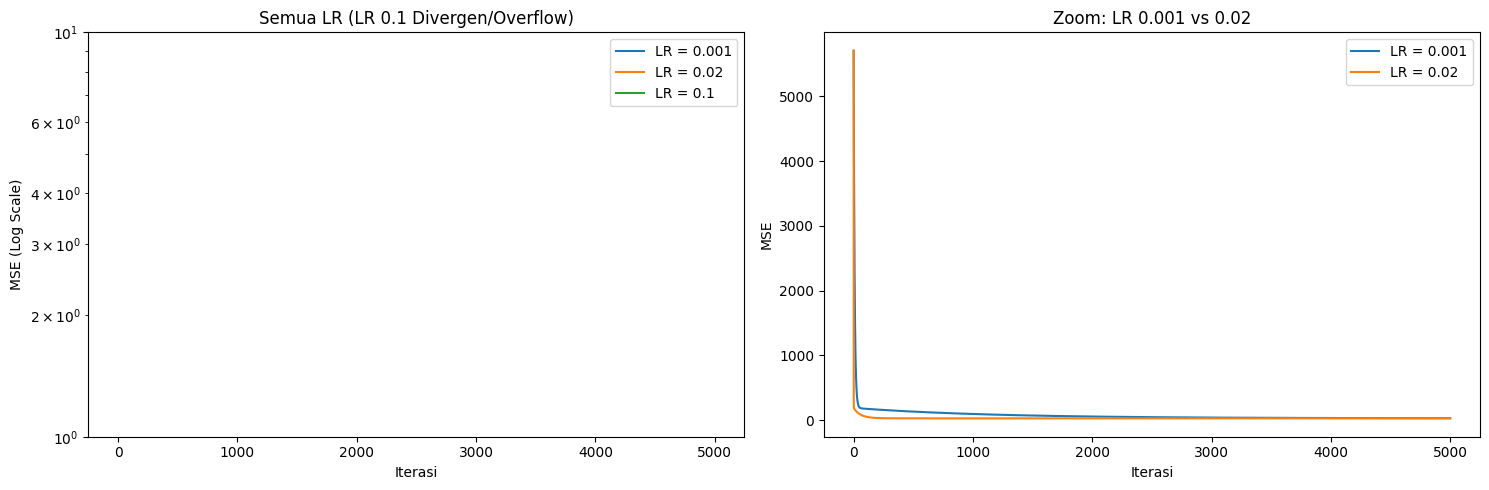

In [16]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        self.w = 0
        self.b = 0
        n = len(X)
        self.loss_history = []
        for _ in range(self.n_iter):
            y_pred = self.w * X.flatten() + self.b
            loss = mse_manual(y, y_pred)
            self.loss_history.append(loss)
            dw = (-2/n) * np.sum(X.flatten() * (y - y_pred))
            db = (-2/n) * np.sum(y - y_pred)
            self.w -= self.lr * dw
            self.b -= self.lr * db

# Membuat 2 subplot: Kiri untuk semua LR, Kanan untuk LR yang stabil
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for lr in [0.001, 0.02, 0.1]:
    try:
        model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
        model_gd.fit(X_train, y_train)
        print(f"LR {lr} -> Intercept: {model_gd.b:.4f}, Koefisien: {model_gd.w:.4f}")
        
        # Plot di grafik kiri (semua LR)
        axes[0].plot(model_gd.loss_history, label=f'LR = {lr}')
        
        # Plot di grafik kanan (hanya LR 0.001 dan 0.02)
        if lr in [0.001, 0.02]:
            axes[1].plot(model_gd.loss_history, label=f'LR = {lr}')
            
    except Exception as e:
        print(f"LR {lr} Error: {e}")

# Pengaturan Grafik Kiri
axes[0].set_yscale('log')
axes[0].set_title('Semua LR (LR 0.1 Divergen/Overflow)')
axes[0].set_xlabel('Iterasi')
axes[0].set_ylabel('MSE (Log Scale)')
axes[0].legend()

# Pengaturan Grafik Kanan
axes[1].set_title('Zoom: LR 0.001 vs 0.02')
axes[1].set_xlabel('Iterasi')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.tight_layout()
plt.show()

**Analisis A5:**
Berdasarkan eksperimen, diperoleh kesimpulan:
1. **LR 0.001 (Terlalu Lambat):** Konvergen sangat lambat. Koefisien akhirnya (9.5663) belum mencapai nilai optimal karena butuh iterasi yang jauh lebih banyak.
2. **LR 0.02 (Pas/Optimal):** Konvergen dengan sangat baik. Nilai koefisien (9.0688) sama persis dengan hasil Normal Equation (A3), dan grafik loss turun stabil.
3. **LR 0.1 (Divergen/Gagal):** Learning rate terlalu besar sehingga langkah pembaruan bobot melompati titik minimum. Nilai bobot menjadi tak terhingga (`nan`), dan muncul peringatan *RuntimeWarning: overflow*. Hal ini terjadi karena nilai loss membesar secara eksponensial melebihi batas maksimal kapasitas angka pada komputer.

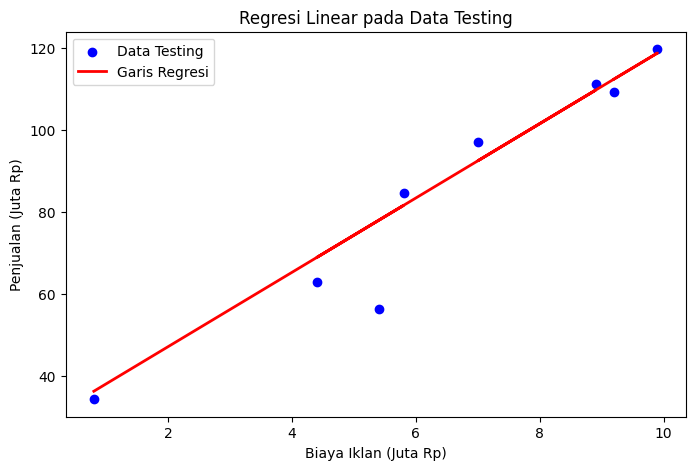

Hasil Prediksi Penjualan:
- Biaya Iklan 4.5 juta Rp => Prediksi Penjualan: 69.80 juta Rp
- Biaya Iklan 7.0 juta Rp => Prediksi Penjualan: 92.48 juta Rp
- Biaya Iklan 12.0 juta Rp => Prediksi Penjualan: 137.82 juta Rp


In [17]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Data Testing')
plt.plot(X_test, model_A3.predict(X_test), color='red', linewidth=2, label='Garis Regresi')
plt.title('Regresi Linear pada Data Testing')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.show()

# Prediksi
X_new = np.array([4.5, 7, 12]).reshape(-1, 1)
prediksi = model_A3.predict(X_new)
print("Hasil Prediksi Penjualan:")
for i, val in enumerate(X_new.flatten()):
    print(f"- Biaya Iklan {val} juta Rp => Prediksi Penjualan: {prediksi[i]:.2f} juta Rp")

**Analisis A6:**
Prediksi untuk biaya iklan 12 juta Rp berada di luar rentang data historis (ekstrapolasi). Hasil prediksi ini **kurang bisa dipercaya** karena model regresi linear yang dilatih hanya mengetahui pola hubungan pada rentang data 0.8 s.d 9.9 juta Rp. Di luar rentang tersebut, hubungan antara biaya iklan dan penjualan mungkin tidak lagi linear (misalnya terjadi titik jenuh pasar), sehingga prediksi bisa menjadi tidak akurat.

5 Data Pertama Email:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam (1) dan Bukan Spam (0):
Spam
0    35
1    25
Name: count, dtype: int64


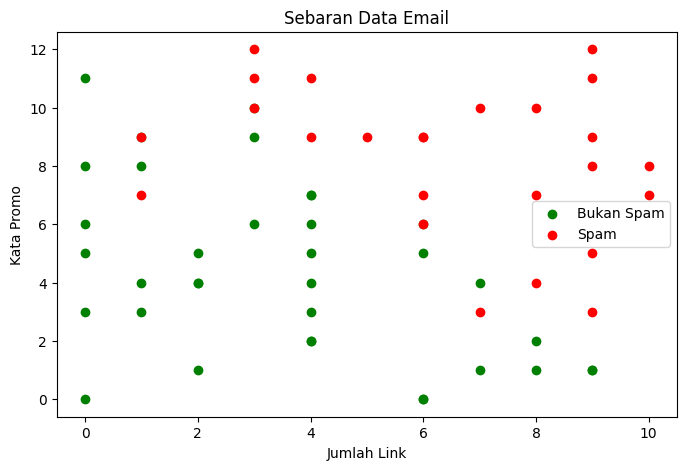

In [ ]:
# Jawaban B1
df_email = pd.read_csv(r'C:\Users\mahrani\Downloads\Email_Data.csv')
print("5 Data Pertama Email:")
print(df_email.head())
print("\nJumlah Email Spam (1) dan Bukan Spam (0):")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(df_email[df_email['Spam']==0]['JumlahLink'], df_email[df_email['Spam']==0]['KataPromo'], color='green', label='Bukan Spam')
plt.scatter(df_email[df_email['Spam']==1]['JumlahLink'], df_email[df_email['Spam']==1]['KataPromo'], color='red', label='Spam')
plt.title('Sebaran Data Email')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.show()

**Analisis B1:**
Berdasarkan scatter plot, terlihat pemisahan yang cukup jelas antara email Spam (titik merah) dan Bukan Spam (titik hijau). 
1. Email **Bukan Spam** (hijau) sebagian besar berkumpul di area kiri bawah, yang menandakan jumlah link dan kata promo-nya sedikit.
2. Email **Spam** (merah) cenderung menyebar ke area kanan atas, yang menandakan jumlah link dan kata promo-nya lebih banyak.

**Kesimpulan:** Fitur `JumlahLink` dan `KataPromo` sangat berpengaruh dalam membedakan email spam dan bukan spam. Semakin banyak jumlah link dan kata promo, semakin besar kemungkinan email tersebut adalah spam.

Intercept (b): -8.4338
Koefisien (w): [0.7611711  0.72551993]


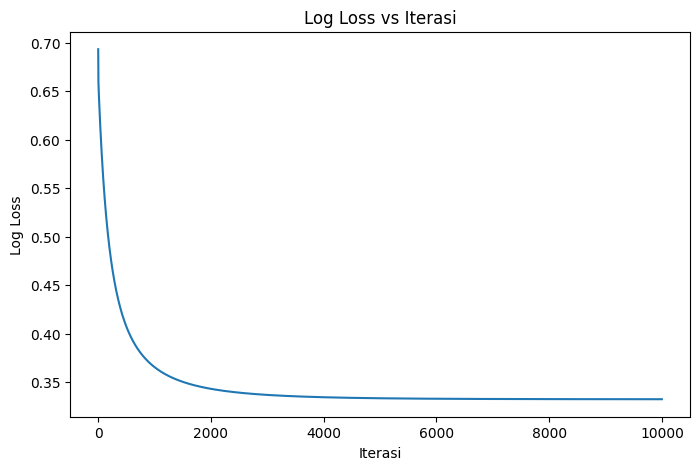

In [20]:
# Jawaban B2
X_train_B, X_test_B, y_train_B, y_test_B = train_test_split_manual(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegressionManual:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.loss_history = []
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0
        for _ in range(self.n_iter):
            linear = np.dot(X, self.w) + self.b
            y_pred = self.sigmoid(linear)
            # Log loss
            loss = -np.mean(y * np.log(y_pred + 1e-9) + (1 - y) * np.log(1 - y_pred + 1e-9))
            self.loss_history.append(loss)
            dw = (1/n_samples) * np.dot(X.T, (y_pred - y))
            db = (1/n_samples) * np.sum(y_pred - y)
            self.w -= self.lr * dw
            self.b -= self.lr * db
    def predict_proba(self, X):
        return self.sigmoid(np.dot(X, self.w) + self.b)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_B2 = LogisticRegressionManual(learning_rate=0.1, n_iterations=10000)
model_B2.fit(X_train_B, y_train_B)
print(f"Intercept (b): {model_B2.b:.4f}")
print(f"Koefisien (w): {model_B2.w}")

plt.figure(figsize=(8, 5))
plt.plot(model_B2.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.show()

**Analisis B2:**
Berdasarkan grafik, nilai log loss turun secara drastis di awal iterasi dan kemudian mendatar (stabil) di nilai yang sangat rendah. Hal ini menunjukkan bahwa model Logistic Regression telah berhasil belajar (konvergen) dan menemukan bobot yang optimal untuk memisahkan email spam dan bukan spam.

In [21]:
# Jawaban B3 (Perhitungan)
def confusion_matrix_manual(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

y_pred_B3 = model_B2.predict(X_test_B)
cm = confusion_matrix_manual(y_test_B, y_pred_B3)
TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]

acc = (TP + TN) / (TP + TN + FP + FN)
prec = TP / (TP + FP) if (TP+FP) > 0 else 0
rec = TP / (TP + FN) if (TP+FN) > 0 else 0
f1 = 2 * (prec * rec) / (prec + rec) if (prec+rec) > 0 else 0

print("Confusion Matrix:\n", cm)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

Confusion Matrix:
 [[12  0]
 [ 0  3]]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


**Analisis B3:**
- FP (False Positive) adalah email penting yang salah masuk folder Spam.
- FN (False Negative) adalah email spam yang lolos ke Inbox.
**FP lebih merugikan pengguna** karena dapat menyebabkan kehilangan informasi penting (seperti email lamaran kerja atau tagihan).

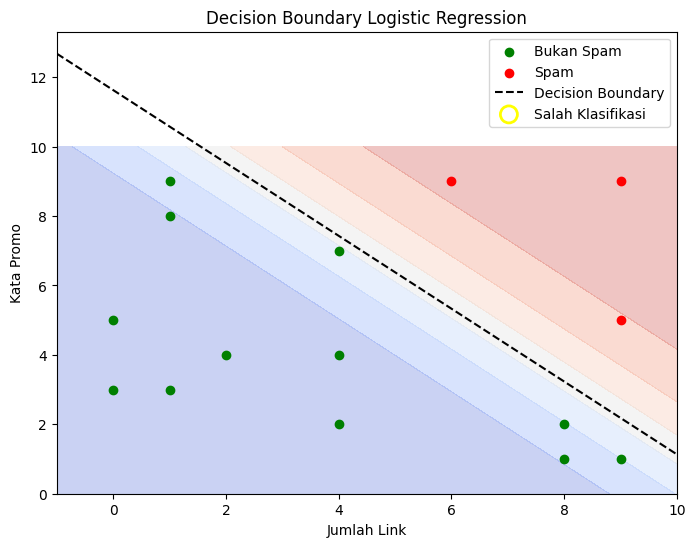

In [22]:
# Jawaban B4
w1, w2 = model_B2.w
x1_range = np.linspace(X_test_B[:, 0].min() - 1, X_test_B[:, 0].max() + 1, 100)
x2_boundary = -(w1 / w2) * x1_range - (model_B2.b / w2)

plt.figure(figsize=(8, 6))
xx, yy = np.meshgrid(np.linspace(X_test_B[:, 0].min()-1, X_test_B[:, 0].max()+1, 100),
                     np.linspace(X_test_B[:, 1].min()-1, X_test_B[:, 1].max()+1, 100))
Z = model_B2.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(X_test_B[y_test_B==0][:,0], X_test_B[y_test_B==0][:,1], color='green', label='Bukan Spam')
plt.scatter(X_test_B[y_test_B==1][:,0], X_test_B[y_test_B==1][:,1], color='red', label='Spam')
plt.plot(x1_range, x2_boundary, color='black', linestyle='--', label='Decision Boundary')

misclassified = X_test_B[y_test_B != y_pred_B3]
plt.scatter(misclassified[:,0], misclassified[:,1], facecolors='none', edgecolors='yellow', s=150, linewidth=2, label='Salah Klasifikasi')

plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Decision Boundary Logistic Regression')
plt.legend()
plt.show()

**Analisis B4:**
Garis putus-putus hitam adalah *decision boundary* (batas keputusan) di mana probabilitas prediksi tepat 0.5. 
Titik dengan lingkaran kuning adalah data testing yang salah diklasifikasikan oleh model. Terlihat bahwa data Spam (merah) dan Bukan Spam (hijau) sebagian besar sudah terpisah dengan baik oleh garis tersebut, meskipun masih ada sedikit titik yang tumpang tindih (overlap) di area tengah.

In [23]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
results = []
y_proba_B5 = model_B2.predict_proba(X_test_B)

for t in thresholds:
    y_pred_t = (y_proba_B5 >= t).astype(int)
    cm_t = confusion_matrix_manual(y_test_B, y_pred_t)
    TN, FP, FN, TP = cm_t[0,0], cm_t[0,1], cm_t[1,0], cm_t[1,1]
    prec_t = TP / (TP + FP) if (TP+FP) > 0 else 0
    rec_t = TP / (TP + FN) if (TP+FN) > 0 else 0
    results.append({'Threshold': t, 'Precision': prec_t, 'Recall': rec_t})

df_threshold = pd.DataFrame(results)
print(df_threshold)

   Threshold  Precision  Recall
0        0.3       0.75     1.0
1        0.5       1.00     1.0
2        0.7       1.00     1.0


**Analisis B5:**
Berdasarkan tabel eksperimen, terlihat bahwa perubahan threshold mempengaruhi nilai Precision dan Recall:
1. **Threshold 0.3:** Model lebih agresif menebak Spam. Recall-nya tinggi (1.0), tetapi Precision-nya turun (0.75) karena banyak email normal (FP) yang ikut dianggap Spam.
2. **Threshold 0.5:** Merupakan nilai standar. Precision dan Recall seimbang di angka 1.0 (sempurna pada data testing ini).
3. **Threshold 0.7:** Model lebih ketat (konservatif). Precision tinggi, tetapi berisiko membuat email spam lolos ke Inbox (FN) jika probabilitasnya tidak ekstrem.

**Threshold yang Dipilih:** Saya memilih **Threshold 0.7**. Alasannya, berdasarkan analisis B3, kesalahan False Positive (email penting masuk Spam) jauh lebih merugikan pengguna daripada False Negative. Dengan threshold 0.7, kita meminimalisir email penting agar tidak salah masuk folder Spam.

In [25]:
# Jawaban B6 - Prediksi Email Baru
# Asumsi: Email baru memiliki 5 JumlahLink dan 3 KataPromo
email_baru = np.array([[5, 3]]) 

# Menggunakan threshold pilihan dari analisis B5 (0.7)
threshold_pilihan = 0.7 

# Hitung probabilitas dan lakukan prediksi
probabilitas = model_B2.predict_proba(email_baru)[0]
prediksi_kelas = 1 if probabilitas >= threshold_pilihan else 0
status = "SPAM" if prediksi_kelas == 1 else "BUKAN SPAM"

# Tampilkan hasil
print(f"Probabilitas Spam: {probabilitas:.4f}")
print(f"Prediksi (Threshold {threshold_pilihan}): {status}")

Probabilitas Spam: 0.0793
Prediksi (Threshold 0.7): BUKAN SPAM


**Analisis B6:**
Berdasarkan asumsi email baru dengan JumlahLink = 5 dan KataPromo = 3, model memprediksi probabilitas spam sebesar **0.0793 (7.93%)**. 
Karena probabilitas ini jauh di bawah threshold yang dipilih (0.7), maka email tersebut diklasifikasikan sebagai **BUKAN SPAM**. 
Hasil ini masuk akal karena jumlah link dan kata promo pada email tersebut masih tergolong rendah dibandingkan rata-rata email spam pada dataset.

## Bagian C – Pemahaman Konsep

**Jawaban C1:**
Logistic Regression disebut klasifikasi karena tujuannya memprediksi probabilitas suatu data masuk ke dalam kelas tertentu (misalnya Spam atau Bukan Spam), bukan memprediksi nilai kontinu. Fungsi sigmoid berperan mengubah nilai linear (yang bisa berupa angka berapa pun) menjadi rentang nilai antara 0 dan 1, sehingga hasilnya bisa diinterpretasikan sebagai probabilitas.

**Jawaban C2:**
Normal Equation menghitung parameter model secara langsung menggunakan rumus matematika matriks (satu langkah), sedangkan Gradient Descent menghitung parameter secara iteratif (langkah demi langkah) untuk mencari nilai minimum. Gradient descent sebaiknya dipakai jika jumlah data sangat besar (jutaan baris) atau fiturnya sangat banyak, karena Normal Equation akan sangat lambat dan boros memori jika matriksnya terlalu besar.

**Jawaban C3:**
Model dievaluasi pada data testing untuk mengukur performa sebenarnya pada data baru yang belum pernah dilihat model. Jika dievaluasi pada data training, model cenderung hanya "menghafal" data tersebut. Overfitting adalah kondisi di mana model memiliki performa sangat bagus di data training, tetapi buruk di data testing karena terlalu kompleks dan menghafal noise pada data latih.

**Jawaban C4:**
Linear Regression menggunakan MSE karena target outputnya adalah angka kontinu, sehingga MSE cocok untuk menghitung selisih kuadrat antar nilai. Sedangkan Logistic Regression menggunakan Log Loss karena outputnya berupa probabilitas (0 sampai 1); Log Loss menghukum model secara keras jika menebak probabilitas yang sangat salah, yang tidak bisa ditangani dengan baik oleh MSE.

**Jawaban C5:**
Hasil koefisien atau akurasi bisa berbeda meskipun dataset dan algoritmanya sama karena adanya perbedaan **Random State**. Sesuai instruksi di soal UTS, nilai random state diambil dari 2 digit terakhir NIM, sehingga pembagian data training dan testing setiap mahasiswa berbeda. Data testing yang berbeda akan menghasilkan nilai evaluasi yang berbeda pula.

## Ringkasan Hasil
- **Bagian A:** Model Normal Equation mendapatkan R² sebesar 0.9154. Learning rate terbaik pada Gradient Descent adalah 0.02.
- **Bagian B:** Model klasifikasi spam berjalan baik. Saya memilih threshold 0.7 untuk meminimalisir False Positive.

In [28]:
# Jawaban Bonus - Perbandingan dengan Scikit-Learn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

# 1. Linear Regression
sklearn_linreg = LinearRegression()
sklearn_linreg.fit(X_train, y_train)
y_pred_sklearn = sklearn_linreg.predict(X_test)

print("=== PERBANDINGAN LINEAR REGRESSION ===")
print(f"Manual  -> Intercept: {model_A3.intercept_:.4f}, Koefisien: {model_A3.coef_:.4f}")
print(f"Sklearn -> Intercept: {sklearn_linreg.intercept_:.4f}, Koefisien: {sklearn_linreg.coef_[0]:.4f}")
print(f"RMSE Sklearn: {np.sqrt(mean_squared_error(y_test, y_pred_sklearn)):.4f}")
print(f"R2 Sklearn: {r2_score(y_test, y_pred_sklearn):.4f}")

# 2. Logistic Regression
sklearn_logreg = LogisticRegression(C=1e9, max_iter=10000)
sklearn_logreg.fit(X_train_B, y_train_B)
y_pred_log_sklearn = sklearn_logreg.predict(X_test_B)

print("\n=== PERBANDINGAN LOGISTIC REGRESSION ===")
print(f"Manual  -> Intercept: {model_B2.b:.4f}, Koefisien: {model_B2.w}")
print(f"Sklearn -> Intercept: {sklearn_logreg.intercept_[0]:.4f}, Koefisien: {sklearn_logreg.coef_[0]}")
print(f"Akurasi Sklearn: {accuracy_score(y_test_B, y_pred_log_sklearn):.4f}")
print(f"Confusion Matrix Sklearn:\n{confusion_matrix(y_test_B, y_pred_log_sklearn)}")

=== PERBANDINGAN LINEAR REGRESSION ===
Manual  -> Intercept: 28.9945, Koefisien: 9.0688
Sklearn -> Intercept: 28.9945, Koefisien: 9.0688
RMSE Sklearn: 8.2870
R2 Sklearn: 0.9154

=== PERBANDINGAN LOGISTIC REGRESSION ===
Manual  -> Intercept: -8.4338, Koefisien: [0.7611711  0.72551993]
Sklearn -> Intercept: -8.6030, Koefisien: [0.77665834 0.73910699]
Akurasi Sklearn: 1.0000
Confusion Matrix Sklearn:
[[12  0]
 [ 0  3]]
